In [ ]:
import pandas as pd
import numpy as np

df = pd.DataFrame({
    'Age': [25, 30, np.nan, 40, 35],
    'Department': ['HR', 'Finance', 'Finance', np.nan, 'IT']
})

# Mean imputation
df['Age'] = df['Age'].fillna(df['Age'].mean())

# Mode imputation
df['Department'] = df['Department'].fillna(df['Department'].mode()[0])

print(df)

    Age Department
0  25.0         HR
1  30.0    Finance
2  32.5    Finance
3  40.0    Finance
4  35.0         IT


In [ ]:
import pandas as pd
import numpy as np

df = pd.DataFrame({
    'Age': [25, 30, np.nan, 40, 35],
    'Department': ['HR', 'Finance', 'Finance', np.nan, 'IT']
})

print("Original Dataset:")
print(df)

print("\nForward Fill:")
print(df.ffill())

print("\nBackward Fill:")
print(df.bfill())

Original Dataset:
    Age Department
0  25.0         HR
1  30.0    Finance
2   NaN    Finance
3  40.0        NaN
4  35.0         IT

Forward Fill:
    Age Department
0  25.0         HR
1  30.0    Finance
2  30.0    Finance
3  40.0    Finance
4  35.0         IT

Backward Fill:
    Age Department
0  25.0         HR
1  30.0    Finance
2  40.0    Finance
3  40.0         IT
4  35.0         IT


In [ ]:
import pandas as pd
import numpy as np

df = pd.DataFrame({
    'Age': [25, 30, np.nan, 40, 35],
    'Department': ['HR', 'Finance', np.nan, 'Finance', 'IT']
})

print("Original Dataset:")
print(df)

print("\nAfter Dropping Rows:")
print(df.dropna())

print("\nAfter Dropping Columns:")
print(df.dropna(axis=1))

Original Dataset:
    Age Department
0  25.0         HR
1  30.0    Finance
2   NaN        NaN
3  40.0    Finance
4  35.0         IT

After Dropping Rows:
    Age Department
0  25.0         HR
1  30.0    Finance
3  40.0    Finance
4  35.0         IT

After Dropping Columns:
Empty DataFrame
Columns: []
Index: [0, 1, 2, 3, 4]


In [ ]:
import pandas as pd

df = pd.DataFrame({
    'ID': [1, 2, 2, 3, 4, 4],
    'Name': ['Alice', 'Bob', 'Bob', 'Charlie', 'David', 'David'],
    'Age': [25, 30, 30, 35, 40, 40]
})

print("Original Data:")
print(df)

print("\nAfter Exact Duplicate Removal:")
print(df.drop_duplicates())

Original Data:
   ID     Name  Age
0   1    Alice   25
1   2      Bob   30
2   2      Bob   30
3   3  Charlie   35
4   4    David   40
5   4    David   40

After Exact Duplicate Removal:
   ID     Name  Age
0   1    Alice   25
1   2      Bob   30
3   3  Charlie   35
4   4    David   40


In [ ]:
import pandas as pd

df = pd.DataFrame({
    'ID': [1, 2, 2, 3, 4, 4, 5],
    'Name': ['Alice', 'Bob', 'Bob', 'Charlie', 'David', 'David', 'David'],
    'Age': [25, 30, 30, 35, 40, 40, 40]
})

print("Original Data:")
print(df)

print("\nDuplicates Removed Based on ID:")
print(df.drop_duplicates(subset=['ID']))

print("\nDuplicates Removed Based on Name:")
print(df.drop_duplicates(subset=['Name']))

Original Data:
   ID     Name  Age
0   1    Alice   25
1   2      Bob   30
2   2      Bob   30
3   3  Charlie   35
4   4    David   40
5   4    David   40
6   5    David   40

Duplicates Removed Based on ID:
   ID     Name  Age
0   1    Alice   25
1   2      Bob   30
3   3  Charlie   35
4   4    David   40
6   5    David   40

Duplicates Removed Based on Name:
   ID     Name  Age
0   1    Alice   25
1   2      Bob   30
3   3  Charlie   35
4   4    David   40


In [ ]:
import pandas as pd

df = pd.DataFrame({
    'Date': ['2025-01-05', '05/01/2025', 'Jan 5, 2025', '2025.01.05']
})

print("Original Data:")
print(df)

df['Date'] = pd.to_datetime(
    df['Date'], format='mixed', errors='coerce', dayfirst=True
).dt.strftime('%Y-%m-%d')

print("\nStandardized Dates:")
print(df)

Original Data:
          Date
0   2025-01-05
1   05/01/2025
2  Jan 5, 2025
3   2025.01.05

Standardized Dates:
         Date
0  2025-01-05
1  2025-01-05
2  2025-01-05
3  2025-01-05


In [ ]:
import pandas as pd

df = pd.DataFrame({
    'Name': ['Alice', 'BOB', 'charlie', 'DAVID']
})

df['Name_lower'] = df['Name'].str.lower()
df['Name_upper'] = df['Name'].str.upper()

print(df)

      Name Name_lower Name_upper
0    Alice      alice      ALICE
1      BOB        bob        BOB
2  charlie    charlie    CHARLIE
3    DAVID      david      DAVID


In [ ]:
import pandas as pd
from scipy.stats import zscore

df = pd.DataFrame({
    'Salary': [25000, 27000, 30000, 28000, 26000, 29000, 200000]
})

df['Z_Score'] = zscore(df['Salary'])

print(df)

print("\nOutliers:")
print(df[abs(df['Z_Score']) > 3])

   Salary   Z_Score
0   25000 -0.449511
1   27000 -0.416389
2   30000 -0.366706
3   28000 -0.399828
4   26000 -0.432950
5   29000 -0.383267
6  200000  2.448650

Outliers:
Empty DataFrame
Columns: [Salary, Z_Score]
Index: []


In [ ]:
import pandas as pd

df = pd.DataFrame({
    'Salary': [25000, 27000, 30000, 28000, 26000, 29000, 200000]
})

Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)

print("\nOutliers:")
print(df[(df['Salary'] < lower) | (df['Salary'] > upper)])

Q1: 26500.0
Q3: 29500.0
IQR: 3000.0
Lower Bound: 22000.0
Upper Bound: 34000.0

Outliers:
   Salary
6  200000


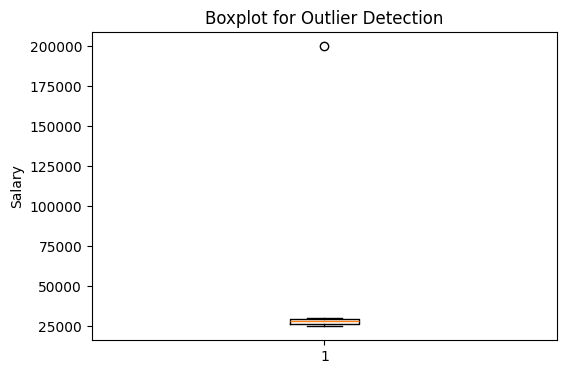

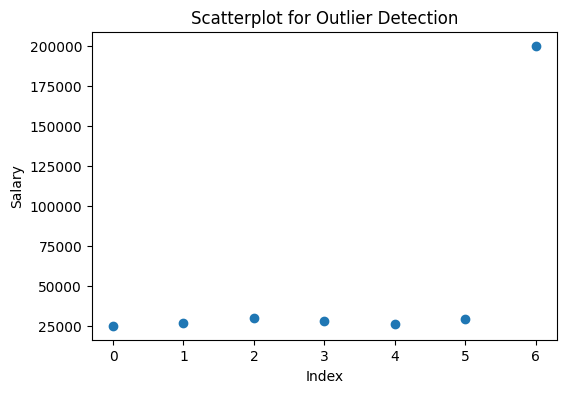

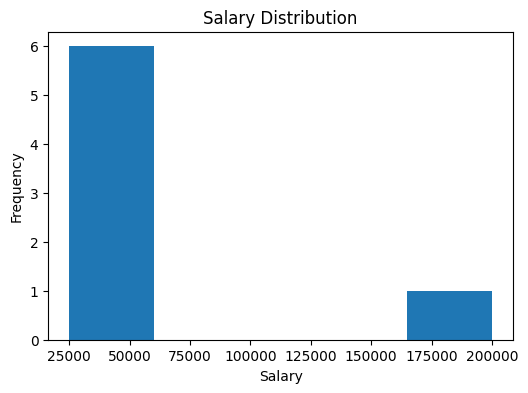

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    'Salary': [25000, 27000, 30000, 28000, 26000, 29000, 200000]
})

# Boxplot
plt.figure(figsize=(6, 4))
plt.boxplot(df['Salary'])
plt.title("Boxplot for Outlier Detection")
plt.ylabel("Salary")
plt.show()

# Scatterplot
plt.figure(figsize=(6, 4))
plt.scatter(range(len(df)), df['Salary'])
plt.title("Scatterplot for Outlier Detection")
plt.xlabel("Index")
plt.ylabel("Salary")
plt.show()

# Histogram
plt.figure(figsize=(6, 4))
plt.hist(df['Salary'], bins=5)
plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Frequency")
plt.show()